In [1]:
# Setup: só lê dados e resultados salvos (sem Earth Engine, sem treino). ~8 min em CPU.
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd() / 'gabriel'))
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
from IPython.display import display, Markdown
import figuras as F
F.estilo()
pd.set_option('display.precision', 3)
c = F.contexto()
tab = F.tabela_scores()

<style>
.reveal img { max-height: 560px; width: auto; max-width: 100%; }
.reveal table { font-size: 0.72em; }
.reveal .jp-OutputArea-output table { font-size: 19px; }
.reveal .jp-OutputArea-output table td, .reveal .jp-OutputArea-output table th { padding: 3px 9px; }
</style>

# Detecção de perturbações na Amazônia sem rótulos

### Features espectrais clássicas + TerraMind + Temporal Transformer Autoencoder

IBM8924 — Projeto de Deep Learning · Grupo 1

*[nomes da dupla]* · apresentação técnica de 06/11/2026

> **Aviso:** os números desta apresentação vêm de uma **sub-área de teste (35,8 km)**. As áreas de estudo completas
> ainda **não foram processadas**; os resultados finais virão depois (ver *Limitações*).

## O problema

- Desmatamento, garimpo, fogo e degradação mudam a floresta **todo trimestre**; os sistemas oficiais (DETER, PRODES)
  chegam com atraso e não veem eventos pequenos.
- Rótulos são **incompletos e atrasados**, e tipos novos de perturbação aparecem.
- Ideia: **aprender como uma área normal evolui** ao longo do tempo e marcar o que foge disso.

```
aprender o "normal"  →  detectar o desconhecido
```

**Pergunta de pesquisa:** um *foundation model* de observação da Terra (TerraMind) melhora a detecção não
supervisionada em relação a features espectrais clássicas? E juntar os dois ajuda?

## Duas implementações, um pipeline

- **Original** (`notebooks/`): engenharia de features espectrais (NDVI, GNDVI, BSI, textura, Fourier), primeiro numa
  tarefa de vigor de pastagem e depois explorando mudança na Amazônia.
- **Gabriel** (`notebooks/gabriel/`): cubo trimestral Sentinel-2 + Sentinel-1, embeddings TerraMind, Transformer AE e
  protocolo de avaliação fixado antes dos resultados.
- **Junção:** as duas descrevem a **mesma célula de 320 m** no mesmo trimestre, e são combinadas de dois jeitos (A e B).

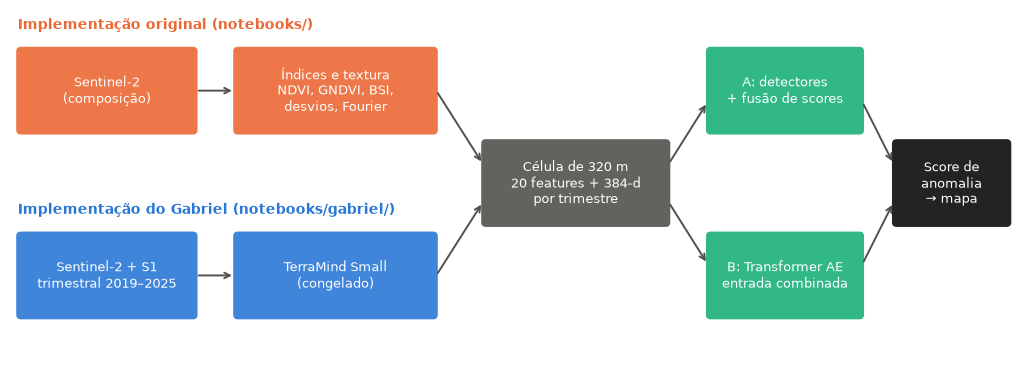

In [2]:
F.fig_pipeline()

## Área de estudo e unidade de análise

- **Tapajós / BR-163 (PA)**: área principal. **Norte de Rondônia**: só teste de generalização.
- Grade UTM de **patches de 2,24 km** (224 × 224 px a 10 m), **28 trimestres** (2019Q1–2025Q4).
- Divisão espacial em **blocos de 4 × 4 patches** (70/15/15): blocos inteiros vão para uma só partição.

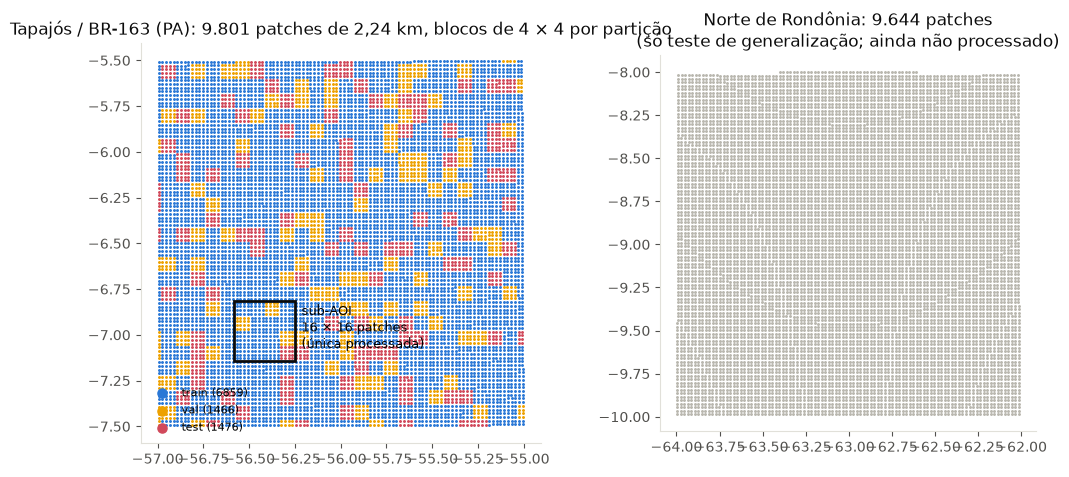

In [3]:
F.fig_area(c)

### Patch → tokens → células

O score é calculado por **célula de 320 m** e o patch recebe o **máximo** das 49 células: a média do patch diluía
eventos pequenos (AUROC 0,57 na média × 0,84 no token, no teste inicial).

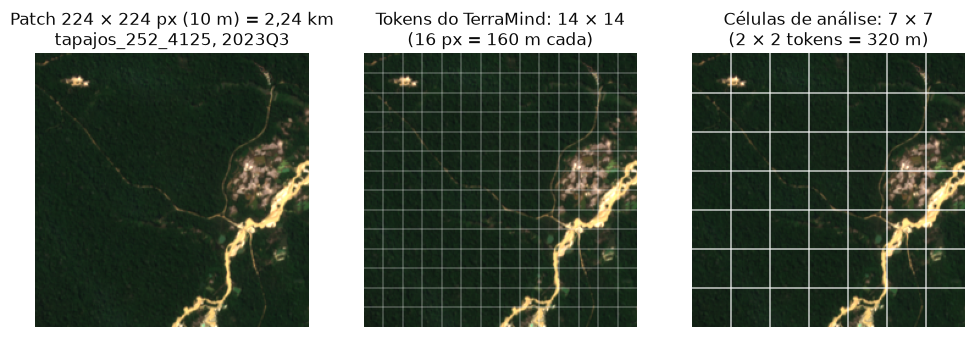

In [4]:
F.fig_patch_celulas(c)

## Como uma imagem se parece

Composição **trimestral** por pixel: mediana das passagens sem nuvem (Cloud Score+ ≥ 0,6), 12 bandas do Sentinel-2.
O Sentinel-1 (radar, VV/VH) enxerga através das nuvens.

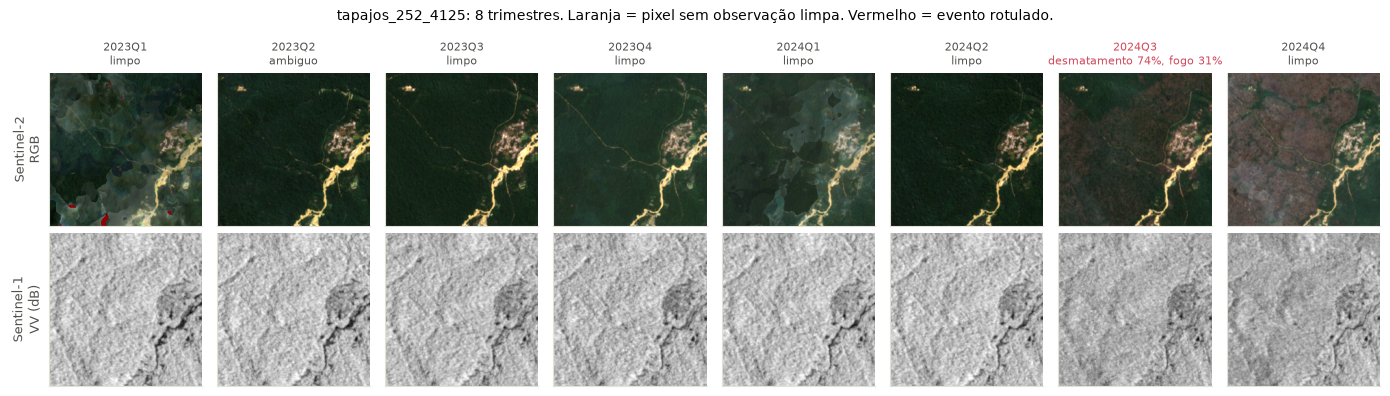

In [5]:
F.fig_serie(c, *F.EXEMPLOS['desmatamento'])

## Antes e depois de um evento

Desmatamento com fogo: o NDVI (vegetação) cai e o BSI (solo exposto) sobe em quase todo o patch.

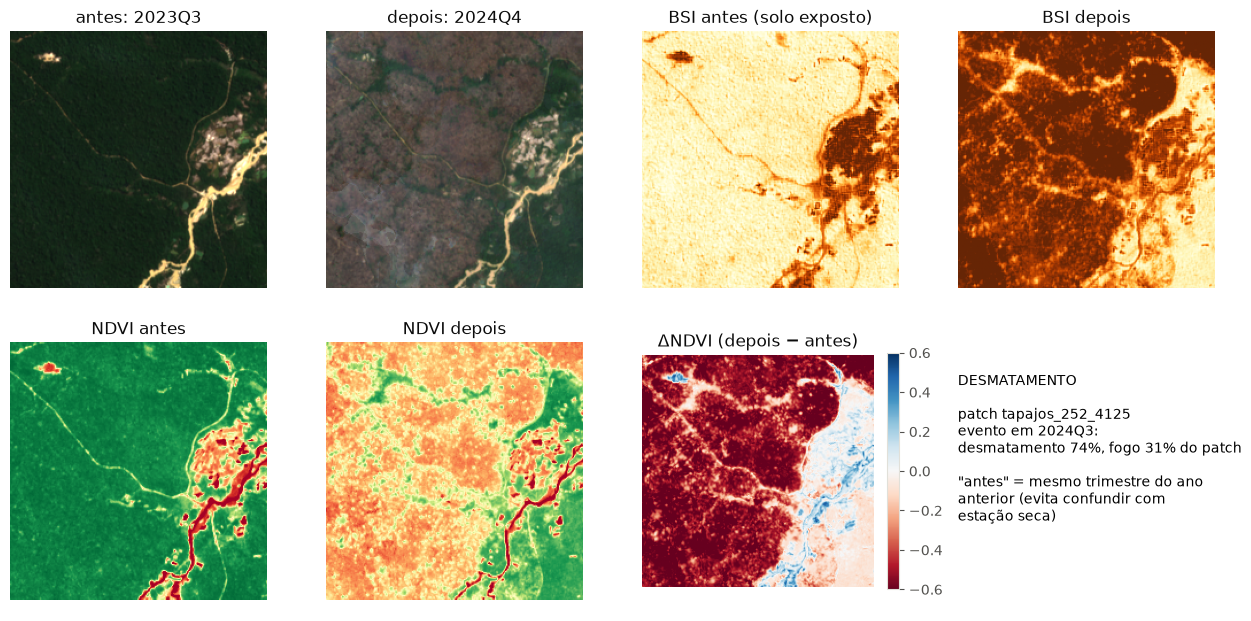

In [6]:
F.fig_antes_depois(c, 'desmatamento')

### Fogo

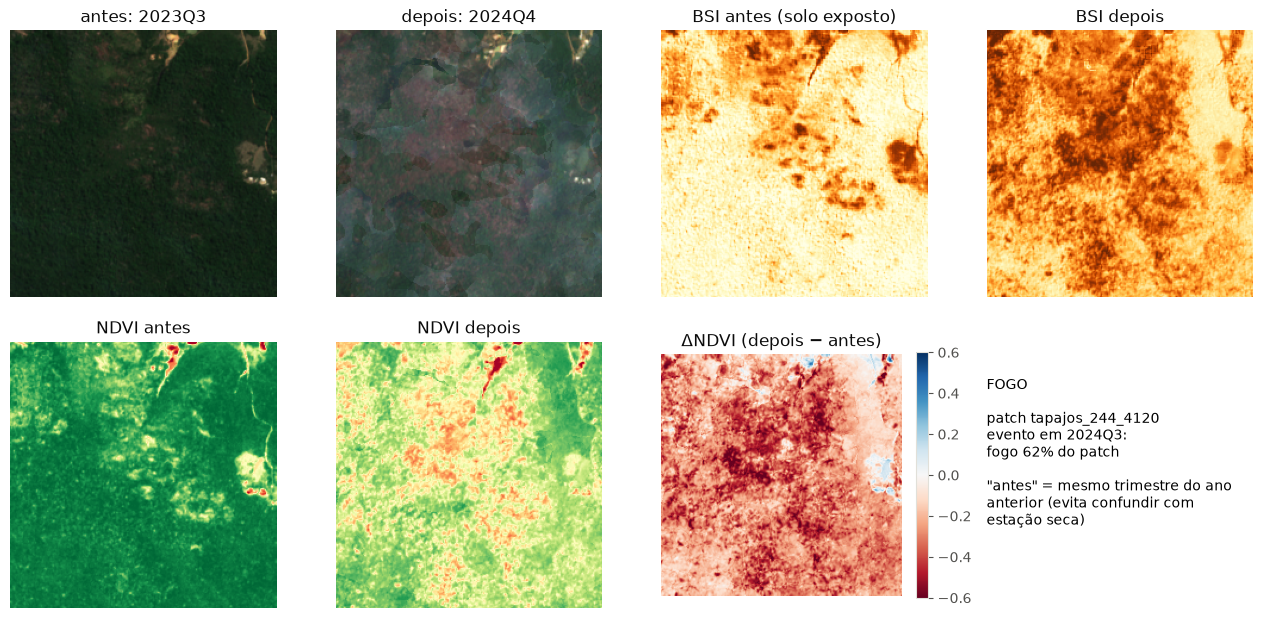

In [7]:
F.fig_antes_depois(c, 'fogo')

### Garimpo: evento pequeno (≈ 5% do patch), quase invisível na média do patch

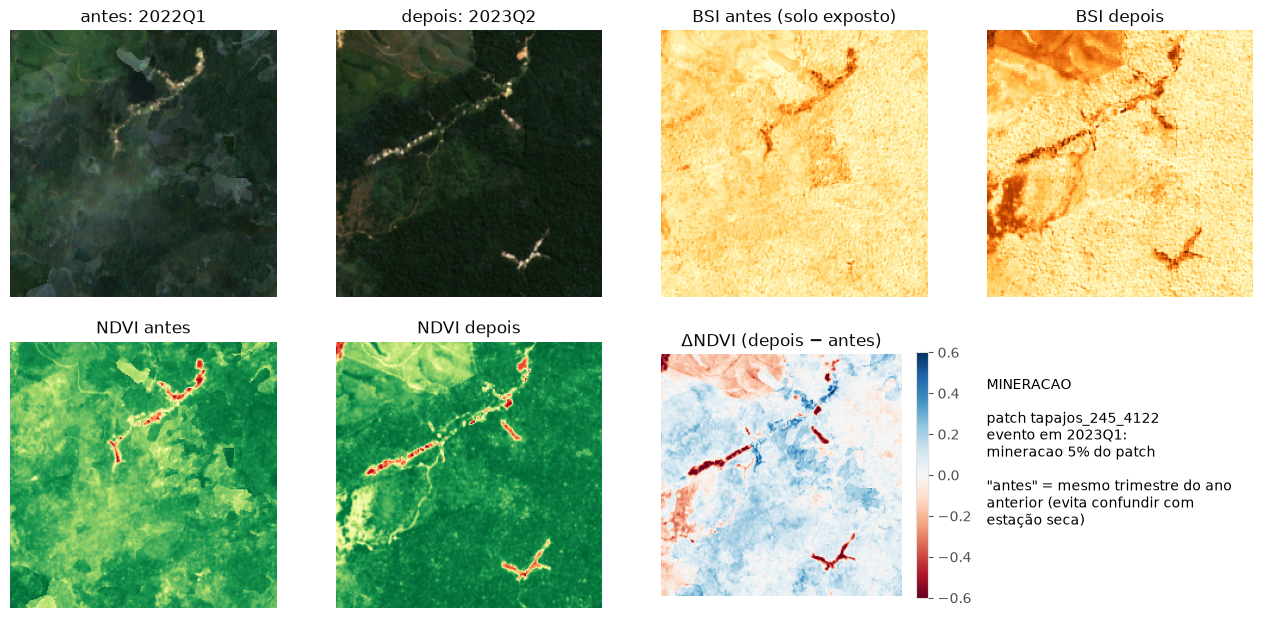

In [8]:
F.fig_antes_depois(c, 'mineracao')

## Rótulos: só para avaliar, o modelo nunca os vê

| Fonte | Tipos | Data |
|---|---|---|
| DETER (INPE) | desmatamento, garimpo, fogo, degradação, corte seletivo | data do alerta |
| PRODES (INPE) | desmatamento | ano PRODES |
| Hansen GFC, MapBiomas | desmatamento, garimpo, água | ano |
| MODIS MCD64A1 | fogo sobre floresta | trimestre |

- **Evento:** ≥ 1% do patch (~5 ha). **Limpo:** nenhuma fonte toca o patch. Entre os dois: ambíguo (fora).
- **Normal de treino:** o patch não tem evento no ano anterior, no próprio ano e no seguinte.
- Avaliação **trimestral** (data do DETER), com a **prevalência real** (~7% de patch-trimestres com evento).

### Patch-trimestres na sub-AOI, por partição e período

In [9]:
s = c.trim[c.trim['patch_id'].isin(c.pids)].merge(c.grade[['patch_id', 'split']], on='patch_id')
display(s.groupby(['split', 'periodo', 'estado']).size().unstack(fill_value=0)
        .rename_axis(index=['partição', 'período'], columns='').loc[['train', 'val', 'test']])

ambiguo  evento  limpo
partição período                        
train    teste         38     166   2100
         treino        59     213   2800
val      teste         10      29    537
         treino        10      82    676
test     teste          0       0    192
         treino         0       0    256

## Engenharia de features (implementação original)

Por célula de 320 m e por trimestre, **20 features**:

| Grupo | Features | Referência |
|---|---|---|
| Nível | média de B2, B3, B4, B8, B11, B12 | — |
| Vegetação | NDVI = (B8 − B4)/(B8 + B4), média e desvio | Rouse et al., 1974 |
| | GNDVI = (B8 − B3)/(B8 + B3) | Gitelson et al., 1996 |
| Solo exposto | BSI = ((B11 + B4) − (B8 + B2)) / ((B11 + B4) + (B8 + B2)) | Rikimaru et al., 2002 |
| Textura | desvio de cada banda; energia de Fourier do NDVI em 4 anéis | notebook 07 |

Origem: as mesmas features separaram **vigor de pastagem** (regressão logística: acurácia 0,64 × 0,25 do
trivial, `03_baseline`). Os detectores usam `[F(t), F(t) − média dos 4 trimestres anteriores]`.

### 6 das 20 features por célula, antes e depois do desmatamento

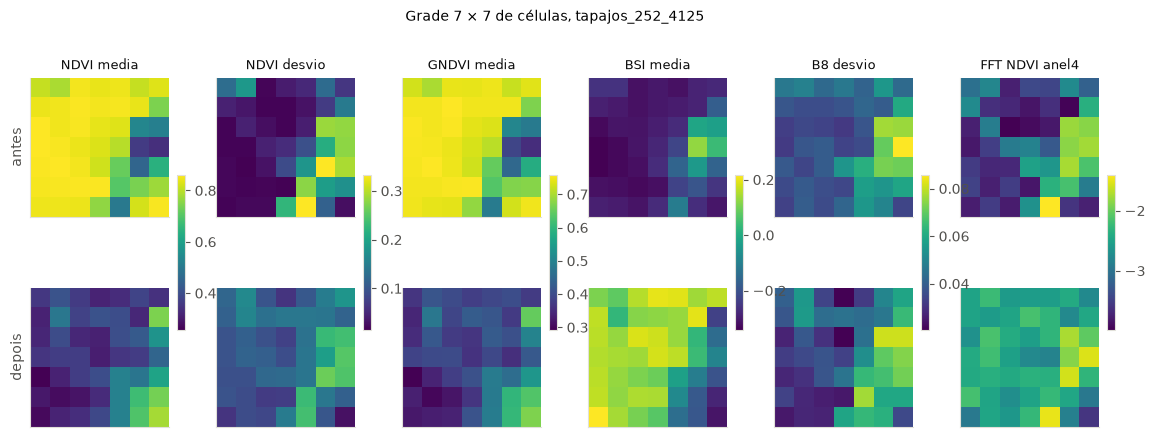

In [10]:
F.fig_features(c)

## Fourier como feature de textura

- NDVI da célula (32 × 32 px), sem a média, com **janela de Hann** (evita a borda falsa da FFT).
- **Perfil radial:** log da energia em 4 anéis de frequência → 4 números por célula.
- **Mudança de textura** = Σ (Δ log E)² nos anéis de alta frequência (> 0,08 ciclo/pixel), contra o histórico.
- No notebook 07, comparar o espectro **inteiro** não localizava mudança (AUROC ≈ 0,5); comparar **localmente** sim.
  Aqui é sempre local (por célula).

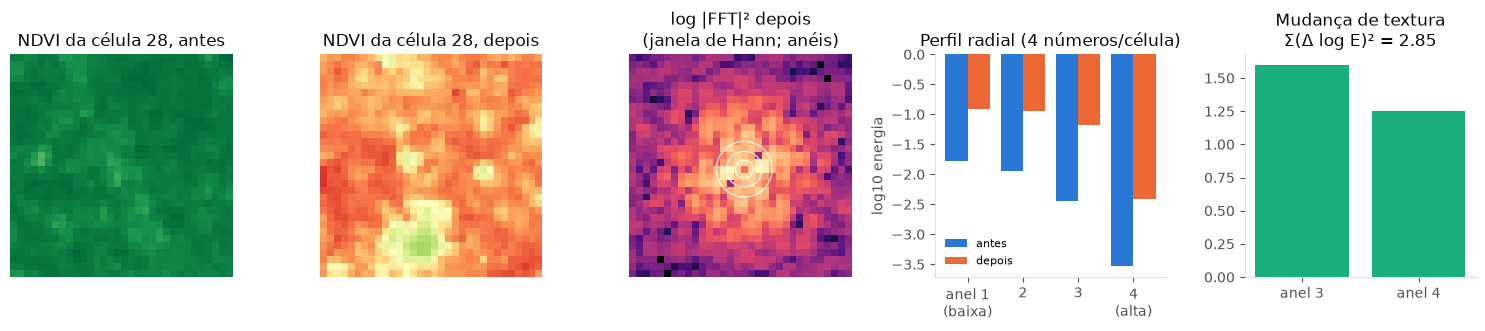

In [11]:
F.fig_fourier(c)

## TerraMind: de imagem para embedding

- *Foundation model* da IBM + ESA, pré-treinado em milhões de imagens multimodais. Usamos o **Small** (22 M de
  parâmetros), **congelado**: nada é treinado nele.
- Entrada 224 × 224 (12 bandas S2 + VV/VH S1, padronizadas com as estatísticas do pré-treino) → **196 tokens de
  384 números**. Média de 2 × 2 tokens = embedding da célula.

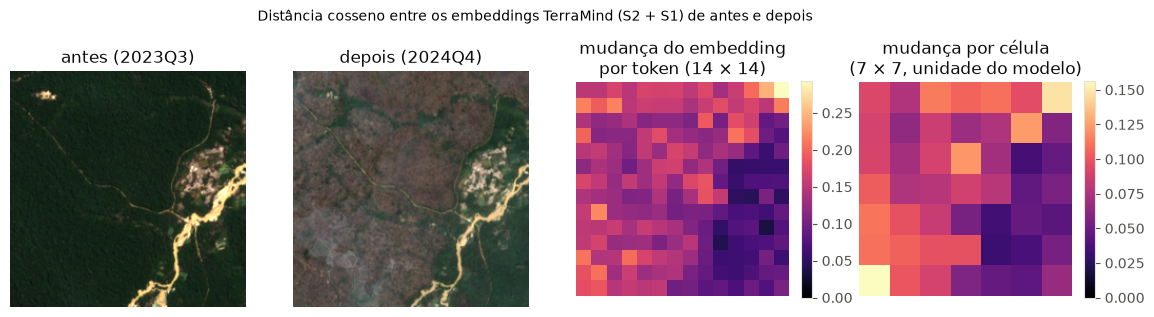

In [12]:
F.fig_terramind(c)

## O modelo: Temporal Transformer Autoencoder

- Treinado **só com sequências normais** (blocos de treino, até 2022). Formulação *masked*: no treino, ~25% dos
  passos de contexto também são escondidos e reconstruídos; a escolha (masked × forecast) foi pela perda de validação.
- 0,9 M de parâmetros; AdamW, lr 1e-3, cosseno, parada antecipada (paciência 6) na perda de validação.

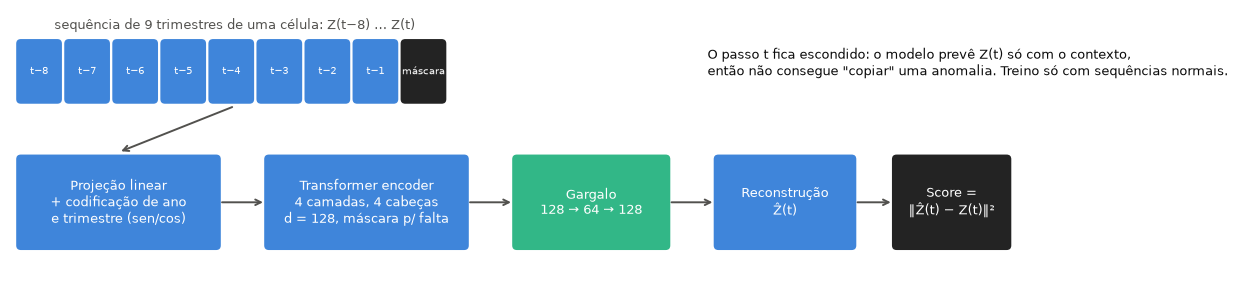

In [13]:
F.fig_ae()

### Curvas de perda (três entradas)

As perdas das três entradas não são comparáveis entre si (dimensões diferentes). O modelo com entrada combinada
(404 dimensões, 26,6 mil sequências) começa a sobreajustar; a parada antecipada guarda a melhor época.
Checkpoint a cada época: um treino interrompido retoma e chega aos **mesmos pesos**.

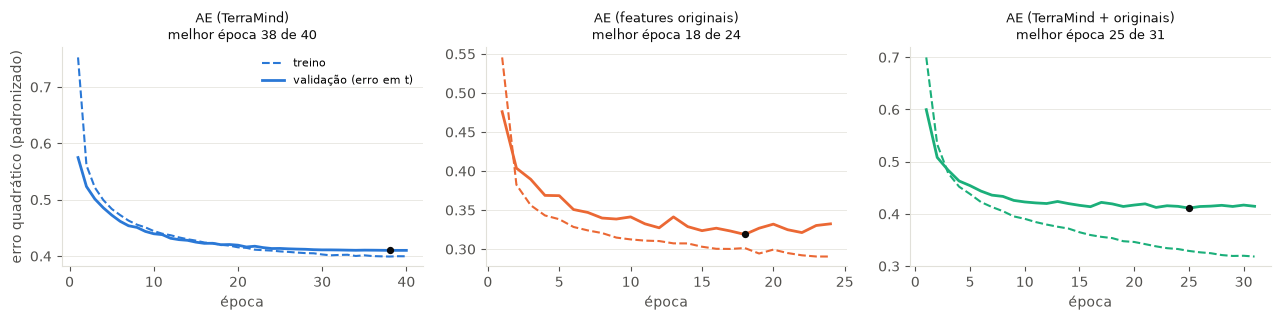

In [14]:
F.fig_curvas()

## Como juntamos as duas implementações

**A. Fusão de scores** (sem retreinar o AE)

$$z_m = \frac{\text{score}_m - \text{mediana}_m}{\text{IQR}_m} \quad\text{(nos normais de validação)}, \qquad
\text{score} = \text{média}(z_{AE},\ z_{\text{IForest nas 20 features}})$$

Na célula, antes do máximo do patch. Percentis foram descartados: saturam em 1 e empatam as anomalias mais fortes.

**B. Entrada combinada** (AE retreinado)

$$Z(t) = [\ \text{TerraMind}_{384}\ |\ \text{features}_{20}\ ], \qquad
\mathcal{L} = 0{,}5\cdot\text{MSE}_{\text{TerraMind}} + 0{,}5\cdot\text{MSE}_{\text{features}}$$

Sem o peso por grupo, as 384 dimensões do TerraMind abafariam as 20 originais.

Regras, combinação principal e pesos **registrados no protocolo antes de qualquer resultado**.

## Por que essas ferramentas

| Escolha | Alternativa | Motivo |
|---|---|---|
| Google Earth Engine | baixar cenas | composição e máscara de nuvem no servidor; baixamos só o recorte |
| Sentinel-2 + Sentinel-1 | só óptico | aberto, 10 m; o radar atravessa nuvem (S2 + S1 > S2 em todos os métodos TerraMind) |
| Trimestral | mensal / anual | mensal tem muitos passos vazios; anual perde o momento do evento |
| TerraMind Small congelado | AlphaEarth; treinar do zero | pesos abertos, controlamos a entrada; sem GPU e sem rótulos para treinar um backbone |
| Célula de 320 m | patch de 2,24 km | a média do patch dilui eventos pequenos |
| Features espectrais | só embedding | interpretáveis, baratas; fortes em fogo e degradação |
| Transformer AE | LSTM, AE comum | máscara para trimestres faltantes; sazonalidade codificada; não copia a anomalia |
| Não supervisionado | classificador | rótulos atrasados e incompletos; detectar o desconhecido |
| Zarr + CPU local | Drive / Colab | ~2 GB livres no Drive; gravação por bloco, retomável |

## Protocolo de avaliação

- **Espacial:** blocos de 8,96 km inteiros em train / val / test. **Temporal:** treino até 2022, avaliação 2023–2025.
- Hiperparâmetros, limiar e referência da fusão: **só com normais de validação**, nunca com rótulos de anomalia.
- Métricas: **AUROC** (ranking, independe do limiar), **AUPRC** (sensível à prevalência baixa), **TPR a 1% de
  falso positivo** (uso operacional), IC 95% por **bootstrap de blocos espaciais**, comparação **pareada** entre métodos.

### Por que não acurácia?

Com ~5–7% de patch-trimestres com evento, um modelo que diz **"tudo normal"** já acerta **~95%**. A acurácia mede
quase só a classe majoritária.

## Teste final: o que dá para medir hoje

| Teste | Situação |
|---|---|
| **Oficial:** split `test` do Tapajós + Rondônia, 2023–2025 | **não existe ainda**: as áreas completas não foram processadas |
| Blocos `test` da sub-AOI (16 patches) | **0 eventos** em 2023–2025: impossível avaliar |
| **Teste limitado (usado aqui):** blocos `val` da sub-AOI, 2023–2025 | **29 eventos**, 537 limpos; nunca vistos (espaço e tempo) |

Regra registrada no protocolo (seção 7) **antes** de calcular. Poucos positivos → ICs largos. **Não é o resultado final.**

### Teste limitado (val, 2023–2025): todas as perturbações, score do patch = máximo das células

In [15]:
res = F.teste_limitado(c, tab)
t = (res[res['tarefa'] == 'todos'].set_index('metodo')
     [['AUROC', 'AUROC_lo', 'AUROC_hi', 'AUPRC', 'TPR@1%FPR', 'n_pos']].sort_values('AUROC', ascending=False))
display(t.rename(columns={'AUROC_lo': 'IC inf.', 'AUROC_hi': 'IC sup.', 'n_pos': 'eventos'}).rename_axis(None))

,AUROC,IC inf.,IC sup.,AUPRC,TPR@1%FPR,eventos
Queda de NDVI,0.769,0.630,0.824,0.157,0.000,29
kNN no delta (TerraMind),0.743,0.627,0.824,0.249,0.069,29
Deep SVDD (features orig.),0.692,0.479,0.722,0.110,0.000,29
Fusão de scores (AE + IForest orig.),0.675,0.609,0.755,0.082,0.000,29
AE (TerraMind),0.668,0.579,0.743,0.092,0.000,29
AE (features originais),0.656,0.532,0.803,0.084,0.034,29
AE (TerraMind + originais),0.632,0.521,0.771,0.077,0.034,29


### Por tipo de perturbação (teste limitado)

In [16]:
pv = res.pivot(index='metodo', columns='tarefa', values='AUROC')
n = res.drop_duplicates('tarefa').set_index('tarefa')['n_pos']
pv.columns = [f'{k} ({int(n[k])} ev.)' for k in pv.columns]
display(pv.loc[t.index].round(3))

,desmatamento (8 ev.),fogo (17 ev.),mineracao (9 ev.),todos (29 ev.)
metodo,,,,
Queda de NDVI,0.726,0.901,0.647,0.769
kNN no delta (TerraMind),0.781,0.890,0.534,0.743
Deep SVDD (features orig.),0.797,0.780,0.539,0.692
Fusão de scores (AE + IForest orig.),0.750,0.767,0.531,0.675
AE (TerraMind),0.753,0.770,0.491,0.668
AE (features originais),0.680,0.729,0.601,0.656
AE (TerraMind + originais),0.663,0.706,0.572,0.632


### Curvas ROC

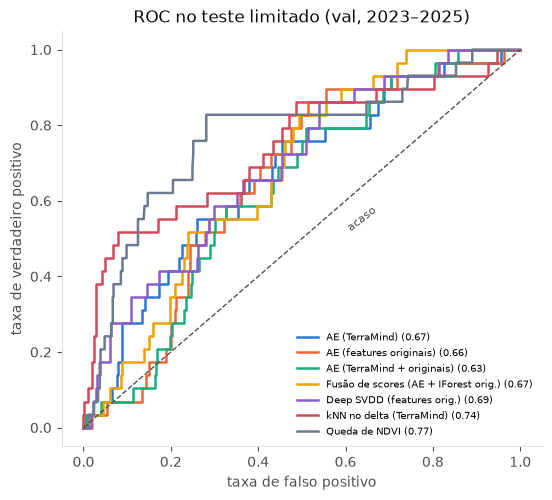

In [17]:
F.fig_roc(c, tab)

### Acurácia no limiar operacional

O limiar é escolhido nos patch-trimestres **limpos de validação de 2021–2022**, para 1% e 5% de falso positivo, e
aplicado em 2023–2025.

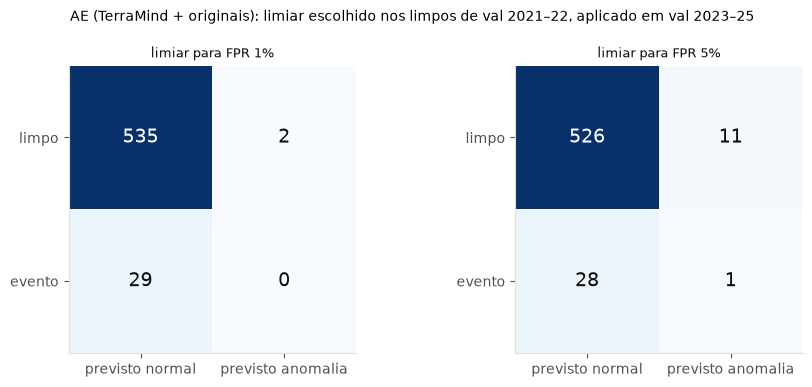

,eventos,VP,FP,FN,VN,acurácia,"acurácia ""tudo normal""",precisão,recall
limiar (FPR alvo),,,,,,,,,
1%,29,0,2,29,535,0.945,0.949,0.000,0.000
5%,29,1,11,28,526,0.931,0.949,0.083,0.034


In [18]:
m = F.matrizes(c, tab)
display(m[['eventos', 'VP', 'FP', 'FN', 'VN', 'acurácia', 'acurácia "tudo normal"', 'precisão', 'recall']])

### Comparação com o diagnóstico no split de treino

Mesmos métodos nos blocos de **treino** em 2023–2025 (166 eventos; holdout só temporal, **diagnóstico**).

In [19]:
d = F.diagnostico_treino()
comp = pd.DataFrame({'diagnóstico (train, 166 ev.)': d[d['tarefa'] == 'todos'].set_index('metodo')['AUROC'],
                     'teste limitado (val, 29 ev.)': t['AUROC']}).loc[t.index]
display(comp.round(3))

,"diagnóstico (train, 166 ev.)","teste limitado (val, 29 ev.)"
metodo,,
Queda de NDVI,0.714,0.769
kNN no delta (TerraMind),0.733,0.743
Deep SVDD (features orig.),0.737,0.692
Fusão de scores (AE + IForest orig.),0.707,0.675
AE (TerraMind),0.684,0.668
AE (features originais),0.721,0.656
AE (TerraMind + originais),0.720,0.632


### Leitura dos resultados (provisória)

- **Detectores simples lideram:** no diagnóstico, Deep SVDD nas features originais (0,74) e kNN no delta do TerraMind
  (0,73); no teste limitado, queda de NDVI (0,77) e kNN no delta do TerraMind (0,74).
- **Juntar as implementações ajudou o AE no diagnóstico:** com as features originais na entrada, o AE foi de 0,68 para
  0,72 (ganho claro em garimpo). No teste limitado, os AEs ficam entre 0,63 e 0,67, com ICs que se sobrepõem.
- **TerraMind × features clássicas:** no mesmo AE, as features originais empatam ou superam o TerraMind. A pergunta de
  pesquisa **continua em aberto** até as áreas completas.
- **No limiar de 1%,** o AE combinado não marca nenhum dos 29 eventos: a acurácia (94,5%) fica abaixo de "tudo normal"
  (94,9%). A 5%, marca 1 de 29 (precisão 8%). Exatamente por isso a acurácia não é a métrica, e o AE ainda não está
  pronto para uso operacional.

## Mapa de anomalia

Um trimestre inteiro da sub-AOI: score de cada célula de 320 m (AE com entrada combinada), lado a lado com a imagem e
os patches que têm evento rotulado.

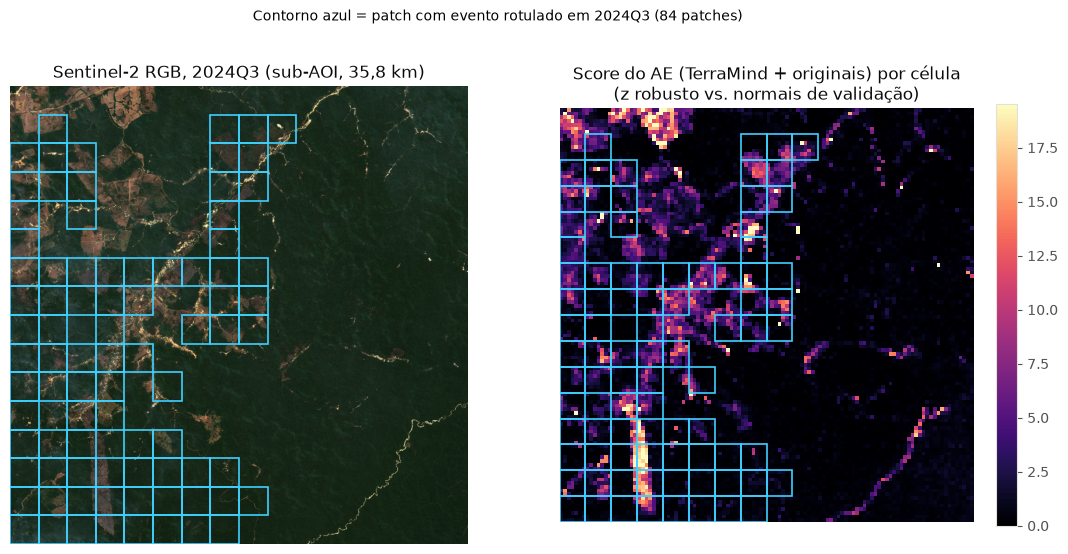

In [20]:
F.fig_mapa(c, '2024Q3')

### O score de um patch ao longo do tempo

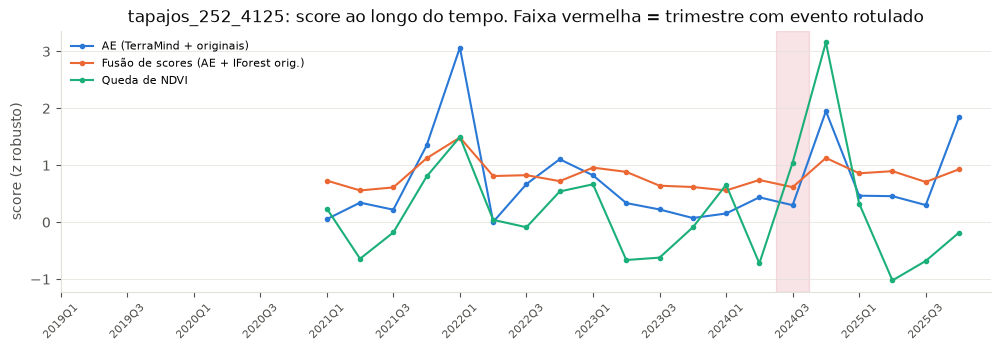

In [21]:
F.fig_serie_score(c, tab)

## Onde o modelo erra

- **Falsos positivos:** expansão de garimpo **visível** em patches que os rótulos chamam de "limpos" → os rótulos têm
  lacunas, e parte do "erro" é acerto não rotulado.
- **Falsos negativos:** eventos de **~1% do patch** (≈ 5 ha), no limite da definição de evento e menores que uma célula.

### Os erros mais fortes do AE (TerraMind + originais) no teste limitado

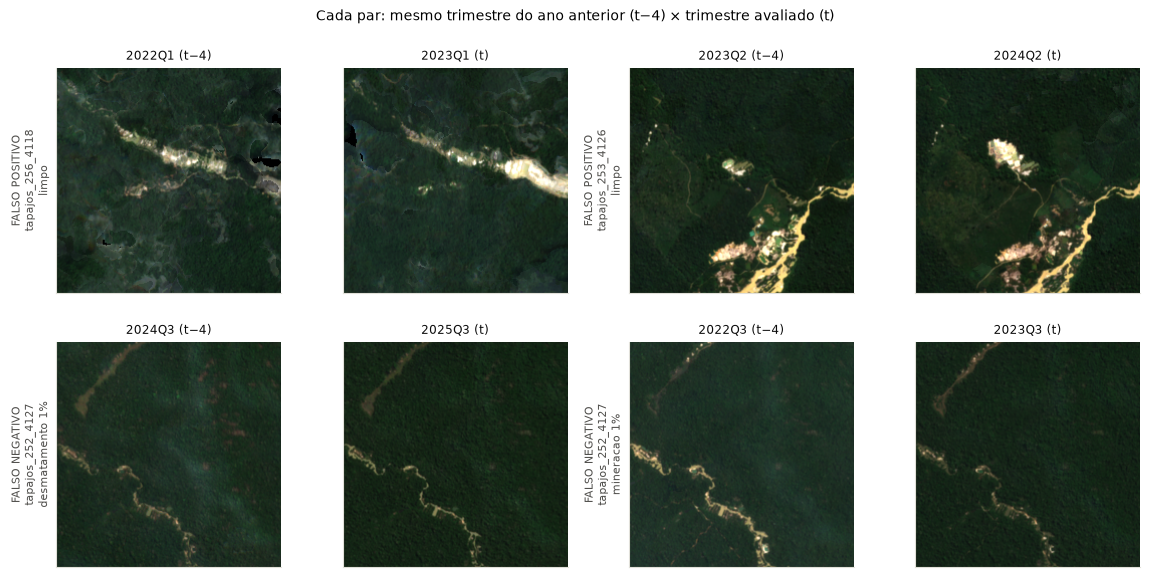

In [22]:
fp, fn = F.fig_erros(c, tab)

## Limitações

**1. As áreas de estudo completas não foram processadas.**

| | Planejado | Feito |
|---|---|---|
| Patches | 19.445 (Tapajós + Rondônia) | **256** (sub-AOI, 1,3%) |
| Patch-trimestres | ~545 mil | 7.168 |
| Tempo estimado | 60–80 h de download do Earth Engine (+ ~19 h de TerraMind em CPU) | ~1 h |

Consequências: sem teste oficial nem de generalização (Rondônia); sub-AOI **escolhida pelos rótulos**; poucos eventos
e ICs largos; normalização por cobertura do solo **não testável** (todos os normais de validação são floresta).
**Os números finais desta apresentação ainda não existem.**

**2. Infraestrutura:** sem GPU local, ~2 GB livres no Drive, download do Earth Engine como gargalo.

**3. Rótulos:** DETER não vê cortes pequenos; PRODES é anual; MapBiomas troca classes parecidas; há eventos visíveis
sem rótulo (slide anterior).

**4. Escala:** 320 m ainda é grande para eventos de poucos hectares.

## Próximos passos

1. **Processar as áreas completas** (`stream_embeddings.py`, já grava as features originais na mesma passada;
   ~3 dias de execução, retomável).
2. **Teste oficial** no Tapajós e de **generalização** em Rondônia, com os três AEs, a fusão e os baselines.
3. **Normalização por cobertura** (pastagem × floresta), testável só com as áreas completas.
4. Mapas de anomalia por trimestre e **antecedência em relação ao DETER**.
5. Se os resultados se mantiverem: artigo para o **IGARSS 2027**.

## Reprodutibilidade e uso de IA

- Ordem: `gabriel/01` → `07` (dados, rótulos, cubo, embeddings, baselines, AE) → `08_fusao` → `09_ae_combinado` →
  este notebook. Protocolo em `gabriel/PROTOCOLO.md`; plano em `PLANO_JUNTAR_DEEP_LEARNING.md`.
- Tudo local em CPU (i5-13420H, 16 GB); versões em `gabriel/requirements-local.txt`; semente 42; cada execução grava
  config, commit e versões em `results/<etapa>/<data>/run.json`.
- Este notebook só lê resultados salvos (~8 min). Slides:
  `jupyter nbconvert notebooks/apresentacao.ipynb --to slides --no-input --SlidesExporter.reveal_width=1280
  --SlidesExporter.reveal_height=860 --SlidesExporter.reveal_scroll=True`.
- **IA generativa:** Claude Code (Anthropic) foi usado para explorar e juntar as duas implementações, escrever código
  (features por célula, fusão, AE com entrada combinada, checkpoints, figuras) e rascunhar textos. Decisões de
  protocolo e resultados revisados pela dupla.